In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate

df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())
print(df.head())

features = ["complexity_score", "team_experience_years"]
X = df[features]
y = df["resolution_hours"]
print("complexity_score and tam experience are available at the intended prediction time")

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 )
print(X_train.shape, X_test.shape)

(192, 2) (48, 2)


In [13]:
def evaluate(model, name):
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name}: MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")


dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
evaluate(dummy, "Baseline (mean)")

print(y_train.mean())    

Baseline (mean): MAE=9.11  RMSE=10.60  R2=-0.021
19.05703125


In [14]:
lin = LinearRegression()
lin.fit(X_train, y_train)
evaluate(lin, "Linear")

Linear: MAE=2.91  RMSE=3.57  R2=0.884


In [26]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_rmse(model):
    scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    return -scores.mean()   

for d in [1, 2, 3]:          
    poly_model = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), StandardScaler(), LinearRegression())
    print("degree", d, "CV RMSE:", round(cv_rmse(poly_model), 3))

degree 1 CV RMSE: 3.909
degree 2 CV RMSE: 3.832
degree 3 CV RMSE: 3.877


In [27]:
poly2 = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression())
poly2.fit(X_train, y_train)
evaluate(poly2, "Poly degree 2")

poly3 = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), LinearRegression())
poly3.fit(X_train, y_train)
evaluate(poly3, "Poly degree 3")

Poly degree 2: MAE=3.02  RMSE=3.74  R2=0.873
Poly degree 3: MAE=3.14  RMSE=3.95  R2=0.858


In [34]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
best_alpha = {}

for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
    best_score = 1e9
    for a in alphas:
        model = make_pipeline(StandardScaler(), Model(alpha=a))
        score = cv_rmse(model)
        print(name, "alpha", a, "CV RMSE", round(score, 3))

        if score < best_score:
            best_score = score
            best_alpha[name] = a
    print("Selected", name, "alpha:", best_alpha[name])


ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha["Ridge"]))
print("----------------------------------------------------------------")
lasso = make_pipeline(StandardScaler(), Lasso(alpha=best_alpha["Lasso"]))
print("----------------------------------------------------------------")
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)
evaluate(ridge, "Ridge")
evaluate(lasso, "Lasso")
print("----------------------------------------------------------------")
print("----------------------------------------------------------------")

lin_scaled = make_pipeline(StandardScaler(), LinearRegression())
lin_scaled.fit(X_train, y_train)

print("Linear coefficients:", lin_scaled[-1].coef_)  
print("Ridge coefficients:", ridge[-1].coef_)
print("Lasso coefficients:", lasso[-1].coef_)

Ridge alpha 0.001 CV RMSE 3.909
Ridge alpha 0.01 CV RMSE 3.909
Ridge alpha 0.1 CV RMSE 3.909
Ridge alpha 1 CV RMSE 3.909
Ridge alpha 10 CV RMSE 3.944
Ridge alpha 100 CV RMSE 5.292
Selected Ridge alpha: 0.1
Lasso alpha 0.001 CV RMSE 3.909
Lasso alpha 0.01 CV RMSE 3.909
Lasso alpha 0.1 CV RMSE 3.912
Lasso alpha 1 CV RMSE 4.141
Lasso alpha 10 CV RMSE 9.884
Lasso alpha 100 CV RMSE 9.884
Selected Lasso alpha: 0.001
----------------------------------------------------------------
----------------------------------------------------------------
Ridge: MAE=2.91  RMSE=3.57  R2=0.884
Lasso: MAE=2.91  RMSE=3.57  R2=0.884
----------------------------------------------------------------
----------------------------------------------------------------
Linear coefficients: [ 8.99482062 -1.07781885]
Ridge coefficients: [ 8.99014697 -1.07734348]
Lasso coefficients: [ 8.99383864 -1.07683687]


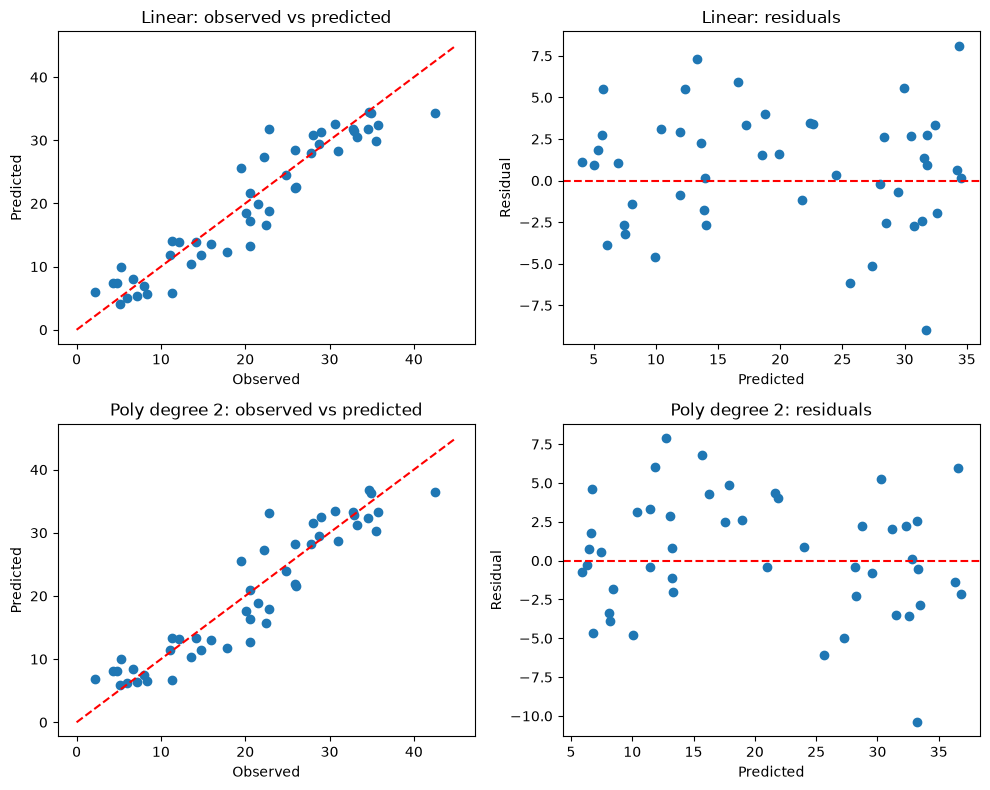

In [35]:
models = {"Linear": lin_scaled, "Poly degree 2": poly2}
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, (name, m) in enumerate(models.items()):
    pred = m.predict(X_test)
    resid = y_test - pred

    axes[i, 0].scatter(y_test, pred)
    axes[i, 0].plot([0, 45], [0, 45], "r--")      
    axes[i, 0].set_xlabel("Observed")
    axes[i, 0].set_ylabel("Predicted")
    axes[i, 0].set_title(name + ": observed vs predicted")

    axes[i, 1].scatter(pred, resid)
    axes[i, 1].axhline(0, color="r", linestyle="--")
    axes[i, 1].set_xlabel("Predicted")
    axes[i, 1].set_ylabel("Residual")
    axes[i, 1].set_title(name + ": residuals")

plt.tight_layout()
plt.show()

In [3]:
print("9. Recommendation")
print(":- I would recommend plain linear regression because ridge and lasso are similar to linear regression and their coefficient barely changed." )
print("----------------------------------------------------------------------")

9. Recommendation
:- I would recommend plain linear regression because ridge and lasso are similar to linear regression and their coefficient barely changed.
----------------------------------------------------------------------


In [24]:
print("Analysis questions")
print("----------------------------------------------------------------------")
print("10:- It shows us the result of always guessing the average which is about 19 hours and any real model has to beat this level. Without it we can't know if the MAE's result is a good one or a bad one. ")
print("----------------------------------------------------------------------")
print("11:- Linear regression has the lowest MSE (2.91) and the lowest RMSE(3.57) and ridge and lasso are tied as well.Here the same model wins both but in general this might not be the case since RMSE punishes big misses more.")
print("----------------------------------------------------------------------")
print("12:- A little of overfitting, degree 2 had a CV RMSE of 3.832 compared with 3.909 of linear but degree 3 went up(3.877). on test, both degree 2 and 3 were worse than linear.")
print("----------------------------------------------------------------------")
print("13:- It did not affect performance and coefficients. both ridge alpha and lasso alpha matched linear regressions test scores and the coefficients did not really shrink.")
print("----------------------------------------------------------------------")
print("14:- Because the penalty is dependent on coefficient size which also depends on features units so unscaled features are penalized poorly but if scaling is present it puts them all on the same scale.")
print("----------------------------------------------------------------------")
print("15:- Lines_changed is a leakage risk bacause it's only known after resolution,therefore it was left out. complexity_score and team_experience were the only ones used.")
print("----------------------------------------------------------------------")
print("16:- No. this means training on new data and tested on older ones which can't happen in real use. and this might result the score becoming too optimistic.")
print("----------------------------------------------------------------------")
print("17:- Maybe testing on new dataset, since the number of data is small so perhaps a larger dataset.")

Analysis questions
----------------------------------------------------------------------
10:- It shows us the result of always guessing the average which is about 19 hours and any real model has to beat this level. Without it we can't know if the MAE's result is a good one or a bad one. 
----------------------------------------------------------------------
11:- Linear regression has the lowest MSE (2.91) and the lowest RMSE(3.57) and ridge and lasso are tied as well.Here the same model wins both but in general this might not be the case since RMSE punishes big misses more.
----------------------------------------------------------------------
12:- A little of overfitting, degree 2 had a CV RMSE of 3.832 compared with 3.909 of linear but degree 3 went up(3.877). on test, both degree 2 and 3 were worse than linear.
----------------------------------------------------------------------
13:- It did not affect performance and coefficients. both ridge alpha and lasso alpha matched linear r